# Model 2 · 4. Evaluasi (ujian akhir)

Model terpilih dari notebook 3 dinilai **sekali** dengan soal ujian `test_potongan` (795 potongan, sudah bersih dari kembaran).
Angka inilah yang dilaporkan. Sebagai tambahan, dinilai juga dengan 76 foto close-up (`test`). *Bukan alat diagnosis medis.*

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data'
print('folder proyek:', ROOT)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from ciri_jerawat import NAMA_CIRI, ciri

KELAS = ['Blackheads', 'Cyst', 'Papules', 'Pustules', 'Whiteheads']
SIMPAN = ROOT / 'hasil' / 'model2'
berkas = SIMPAN / 'model2_gabungan_warna_titik_v3.joblib'
if not berkas.exists():
    berkas = ROOT / 'models' / 'model2_gabungan_warna_titik_v3.joblib'
paket = joblib.load(berkas)
model = paket['model']
print('model:', berkas.relative_to(ROOT), '|', paket['ciri'])


def daftar(bagian, hanya_potongan=False):
    p = [(f, i) for i, k in enumerate(KELAS) for f in sorted((DATA / 'jenis_v3' / bagian / k).glob('*'))
         if not hanya_potongan or f.name.startswith('C_')]
    return [f for f, _ in p], np.array([i for _, i in p])


P_UJI, Y_UJI = daftar('test_potongan')
X_UJI = np.load(SIMPAN / 'ciri_warna_titik.npz')['ujian']
assert len(X_UJI) == len(P_UJI)

folder proyek: C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL


model: hasil\model2\model2_gabungan_warna_titik_v3.joblib | warna48+titik12


## 1. Nilai ujian

In [2]:
pred = model.predict(X_UJI)
peluang = model.predict_proba(X_UJI)
akurasi, f1 = accuracy_score(Y_UJI, pred), f1_score(Y_UJI, pred, average='macro')
print(f'Ujian potongan ({len(pred)} soal): akurasi {akurasi:.3f} | macro F1 {f1:.3f}\n')
print(classification_report(Y_UJI, pred, target_names=KELAS, digits=3))
pd.DataFrame([{'ujian': 'test_potongan', 'soal': len(pred), 'akurasi': akurasi, 'macro_F1': f1}]).round(4).to_csv(SIMPAN / 'hasil_ujian.csv', index=False)

Ujian potongan (795 soal): akurasi 0.735 | macro F1 0.715

              precision    recall  f1-score   support

  Blackheads      0.845     0.795     0.819       171
        Cyst      0.667     0.552     0.604        58
     Papules      0.708     0.796     0.749       235
    Pustules      0.737     0.655     0.693       171
  Whiteheads      0.688     0.731     0.709       160

    accuracy                          0.735       795
   macro avg      0.729     0.706     0.715       795
weighted avg      0.737     0.735     0.734       795



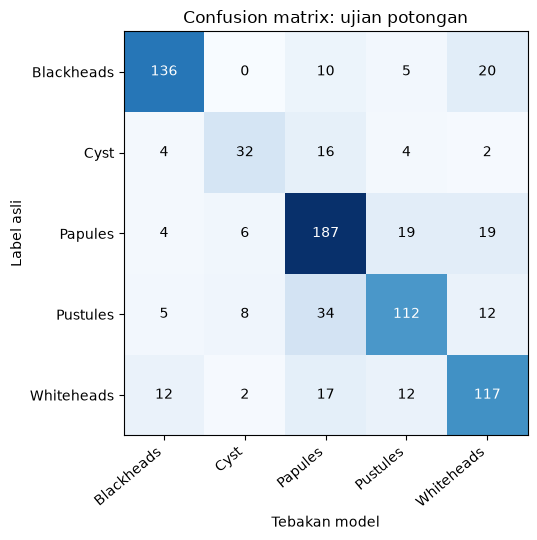

Kesalahan terbanyak:
Pustules -> Papules         34
Blackheads -> Whiteheads    20
Papules -> Pustules         19
Papules -> Whiteheads       19
Whiteheads -> Papules       17


In [3]:
cm = confusion_matrix(Y_UJI, pred)
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5), KELAS, rotation=40, ha='right'); ax.set_yticks(range(5), KELAS)
for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('Tebakan model'); ax.set_ylabel('Label asli'); ax.set_title('Confusion matrix: ujian potongan')
plt.tight_layout(); plt.savefig(SIMPAN / 'confusion_ujian.png', dpi=120); plt.show()

salah = pd.Series([f'{KELAS[a]} -> {KELAS[b]}' for a, b in zip(Y_UJI, pred) if a != b]).value_counts()
print('Kesalahan terbanyak:'); print(salah.head(5).to_string())

**Cara membaca:** diagonal = benar. Kesalahan terbanyak biasanya Pustules ditebak Papules (sama-sama merah,
titik kuningnya kecil), Blackheads ↔ Whiteheads (keduanya titik kecil), dan Cyst ditebak Papules
(bedanya kedalaman/ukuran, yang tidak terlihat jelas di potongan kecil).

## 2. Ujian tambahan: foto close-up

In [4]:
P_CU, Y_CU = daftar('test')
X_CU = np.stack([ciri(Image.open(p)) for p in P_CU])
p_cu = model.predict(X_CU)
print(f'Close-up ({len(p_cu)} foto): akurasi {accuracy_score(Y_CU, p_cu):.3f} | macro F1 {f1_score(Y_CU, p_cu, average="macro"):.3f}')
print('Close-up berbeda dari potongan (foto dekat, jerawat besar), dan model dilatih sebagian besar dengan potongan, jadi nilainya lebih rendah.')

Close-up (76 foto): akurasi 0.526 | macro F1 0.537
Close-up berbeda dari potongan (foto dekat, jerawat besar), dan model dilatih sebagian besar dengan potongan, jadi nilainya lebih rendah.


## 3. Perbandingan dengan model lain (soal ujian yang sama)

In [5]:
banding = pd.DataFrame([
    ('Random Forest, 48 ciri warna', 0.645, None),
    ('Random Forest, 60 ciri warna+titik', 0.701, None),
    ('YOLOv8n-cls (deep learning, model 2 lama)', 0.703, 0.691),
    ('Gabungan RF+ET+HGB, 60 ciri (dipakai)', round(akurasi, 3), round(f1, 3)),
], columns=['model', 'akurasi ujian', 'macro F1'])
print(banding.to_string(index=False))
print('Angka selain baris terakhir berasal dari percobaan sebelumnya pada soal ujian yang sama.')

                                    model  akurasi ujian  macro F1
             Random Forest, 48 ciri warna          0.645       NaN
       Random Forest, 60 ciri warna+titik          0.701       NaN
YOLOv8n-cls (deep learning, model 2 lama)          0.703     0.691
    Gabungan RF+ET+HGB, 60 ciri (dipakai)          0.735     0.715
Angka selain baris terakhir berasal dari percobaan sebelumnya pada soal ujian yang sama.


## 4. Ciri yang paling dipakai model
Diambil dari bagian Random Forest di dalam model gabungan.

Porsi kepentingan 12 ciri titik: 32%


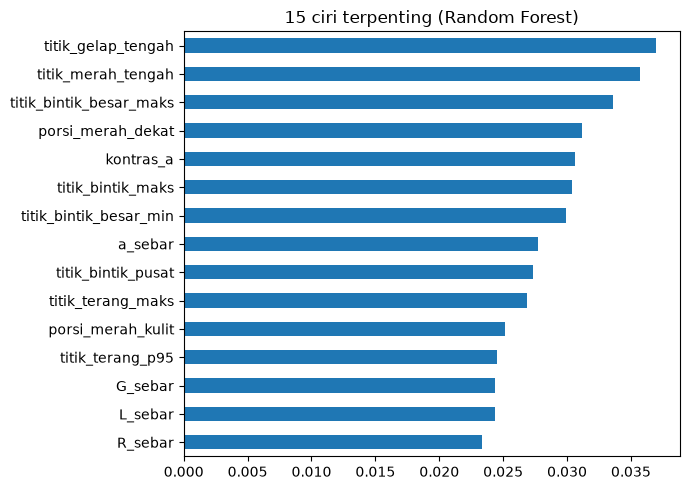

In [6]:
rf = model.named_estimators_['rf']
pent = pd.Series(rf.feature_importances_, index=NAMA_CIRI).sort_values(ascending=False)
print(f"Porsi kepentingan 12 ciri titik: {pent[[n for n in NAMA_CIRI if n.startswith('titik') or n.startswith('porsi_merah_')]].sum():.0%}")
pent.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title='15 ciri terpenting (Random Forest)')
plt.tight_layout(); plt.show()

## 5. Contoh tebakan (hijau = benar, merah = salah)

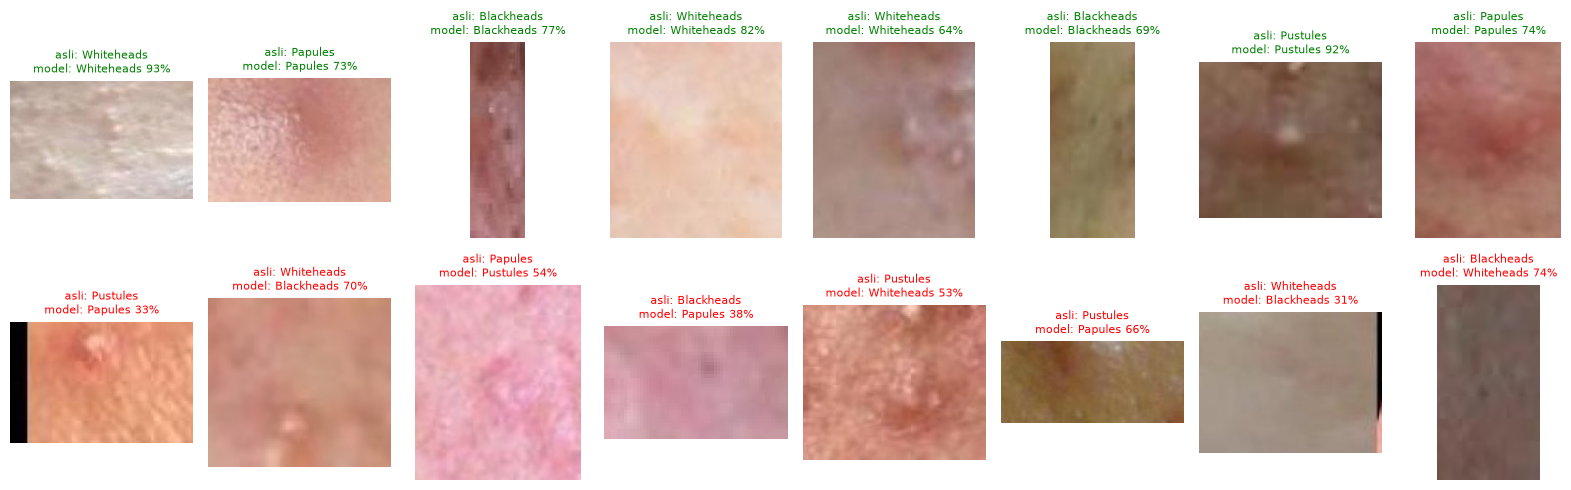

In [7]:
rng = np.random.default_rng(1)
pilih = np.concatenate([rng.choice(np.where(pred == Y_UJI)[0], 8, replace=False), rng.choice(np.where(pred != Y_UJI)[0], 8, replace=False)])
fig, ax = plt.subplots(2, 8, figsize=(16, 5))
for a, i in zip(ax.flat, pilih):
    a.imshow(Image.open(P_UJI[i]).convert('RGB')); a.axis('off')
    a.set_title(f'asli: {KELAS[Y_UJI[i]]}\nmodel: {KELAS[pred[i]]} {peluang[i].max():.0%}', fontsize=8,
                color='green' if pred[i] == Y_UJI[i] else 'red')
plt.tight_layout(); plt.show()

## Kesimpulan
- Model 2 final: **Gabungan RF + ET + HGB** dengan 60 ciri, akurasi ujian **0,735**, macro F1 **0,715**.
- Lebih baik dari model deep learning YOLOv8n-cls pada soal yang sama (0,703).
- Jenis terlemah: **Cyst** (F1 sekitar 0,60) dan **Pustules**. Penyebab utama: foto kecil (detail hilang),
  kedalaman jerawat tidak terlihat di foto, dan label antar sumber dataset tidak selalu konsisten.
- Target tim 80% belum tercapai. Yang paling menjanjikan: memperbaiki label train dan menambah foto Cyst dari sumber lain
  dengan resolusi lebih besar.